# TED-LIUM Release 3 — ASR cohort EDA

This notebook **reproduces plots and tables from the executed 2026-10-03 full-corpus EDA receipt**. It verifies the retained JSON hash before displaying results. The original 270,323-row Arrow snapshot was removed locally, so this run is **not** a new row-level scan or a completed waveform qualification. The raw-source cells below still show a visible HOLD while Arrow is absent. A separate section reopens and verifies a retained 50-unit historical WAV bundle; it is a sampled media audit, not a fresh Arrow scan.

Unit: source segment. Source splits: train, validation, native test. Scorable ASR cohort: 507 validation + 1,155 native test segments; train is descriptive only. Native-test references were previously accessed; this split cannot be called unseen. No model is run here.

In [10]:
from pathlib import Path
import hashlib, json, os
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

def find_root():
    override = os.environ.get("BENCHMARK_ROOT")
    candidates = [Path(override)] if override else []
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidates += [base, base / "benchmark"]
    for base in candidates:
        if (base / "experiments/outputs/full_corpus_eda_261003/eda_receipt.json").is_file():
            return base.resolve()
    raise FileNotFoundError("Set BENCHMARK_ROOT to the benchmark repository with the retained EDA receipt.")

ROOT = find_root()
OUT = ROOT / "experiments/outputs/full_corpus_eda_261003"
receipt = json.loads((OUT / "eda_receipt.json").read_text(encoding="utf-8"))
payload = (OUT / "tedlium3.json").read_bytes()
digest = hashlib.sha256(payload).hexdigest()
assert digest == receipt["artifact_sha256"]["tedlium3.json"], "EDA JSON hash disagrees with the receipt"
assert receipt["status"] == "executed_full_local_corpus_eda_with_declared_limits"
assert receipt["native_test_reference_aggregates_accessed"] is True
data = json.loads(payload)
splits = {r["source_split"]: r for r in data["source_rows"]}
assert set(splits) == {"train", "validation", "test"}
assert sum(r["rows"] for r in splits.values()) == 270323
print("Verified retained EDA JSON:", digest)
print("Origin:", receipt["status"], "| source splits:", ", ".join(receipt["source_splits_analyzed"]))
print("Historical aggregate step: no new Arrow rows or waveforms read in this step.")

Verified retained EDA JSON: 94a6262db8768771b57aab6deec7a3b822480b13660947464978d89b24973485
Origin: executed_full_local_corpus_eda_with_declared_limits | source splits: train, validation, test
Historical aggregate step: no new Arrow rows or waveforms read in this step.


## 1. Source accounting and exclusion denominators

The original scan covered every retained source row. Valid ASR means positive parsed timing, nonblank reference, and no gap/ignore marker. The aggregate does not contain a row-level exclusion ledger or unusual audio examples.

In [10]:
rows = []
for name in ("train", "validation", "test"):
    r = splits[name]
    rows.append({
        "split": name, "source_rows": r["rows"], "valid_asr": r["valid_asr_rows"],
        "excluded": r["rows"] - r["valid_asr_rows"], "ignore_marker": r["ignore_marker_rows"],
        "gap": r["gap_rows"], "blank_reference": r["blank_reference_rows"],
        "bad_timing": r["unparseable_or_nonpositive_timing_rows"],
        "missing_speaker": r["missing_speaker_rows"], "missing_source_file": r["missing_source_file_rows"],
        "speakers": r["unique_speakers"], "source_files": r["unique_source_files"],
    })
accounting = pd.DataFrame(rows).set_index("split")
assert (accounting.valid_asr + accounting.excluded == accounting.source_rows).all()
assert accounting.loc["validation", "valid_asr"] == 507
assert accounting.loc["test", "valid_asr"] == 1155
display(accounting)
print("Interpretation: validation excludes 84/591 ignore rows; test excludes 314/1,469 gap/ignore rows.")
print("Do not sum gap and ignore counts: the same rows can satisfy both flags.")

Interpretation: validation excludes 84/591 ignore rows; test excludes 314/1,469 gap/ignore rows.
Do not sum gap and ignore counts: the same rows can satisfy both flags.


,source_rows,valid_asr,excluded,ignore_marker,gap,blank_reference,bad_timing,missing_speaker,missing_source_file,speakers,source_files
split,,,,,,,,,,,
train,268263,268263,0,0,0,0,0,0,0,2351,2351
validation,591,507,84,84,0,0,0,0,0,29,8
test,1469,1155,314,314,314,0,0,0,0,16,11


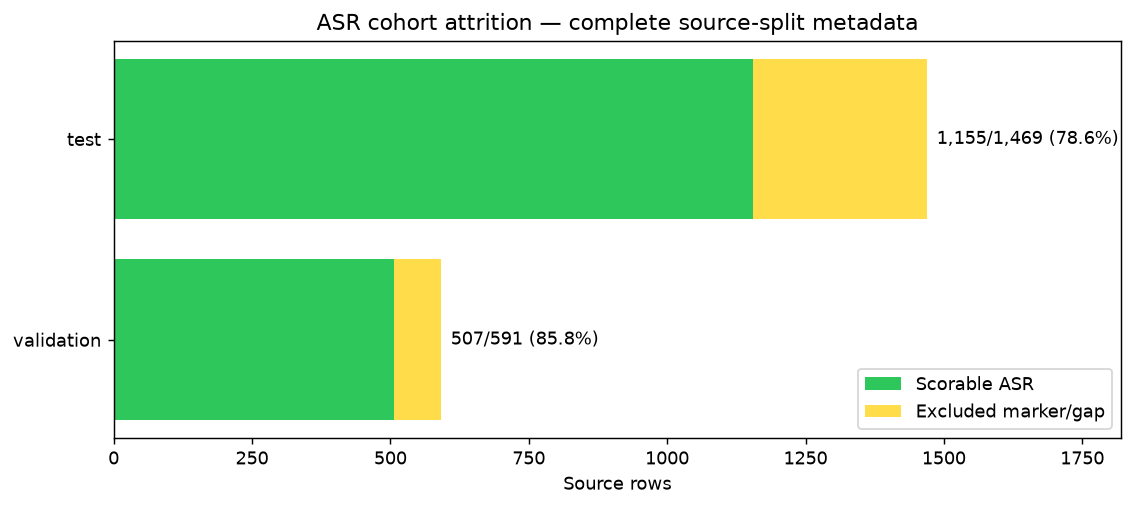

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
names = ["validation", "test"]
valid = [splits[n]["valid_asr_rows"] for n in names]
excluded = [splits[n]["rows"] - splits[n]["valid_asr_rows"] for n in names]
ax.barh(names, valid, color="#2dc75c", label="Scorable ASR")
ax.barh(names, excluded, left=valid, color="#ffdc4a", label="Excluded marker/gap")
for y, n in enumerate(names):
    ax.text(splits[n]["rows"] + 18, y, f'{valid[y]:,}/{splits[n]["rows"]:,} ({valid[y]/splits[n]["rows"]:.1%})', va="center")
ax.set_xlim(0, 1820)
ax.set_xlabel("Source rows")
ax.set_title("ASR cohort attrition — complete source-split metadata")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 2. Input and transcript distributions

Duration histograms include **all source rows**, including gap/ignore markers. Reference-word histograms include only valid ASR rows. The distributions are from the retained full-corpus aggregate; raw examples are unavailable locally.

Interpretation: validation has longer median segments/references than train; split mix differs.
Duration sums are not unique audio hours because intervals overlap.


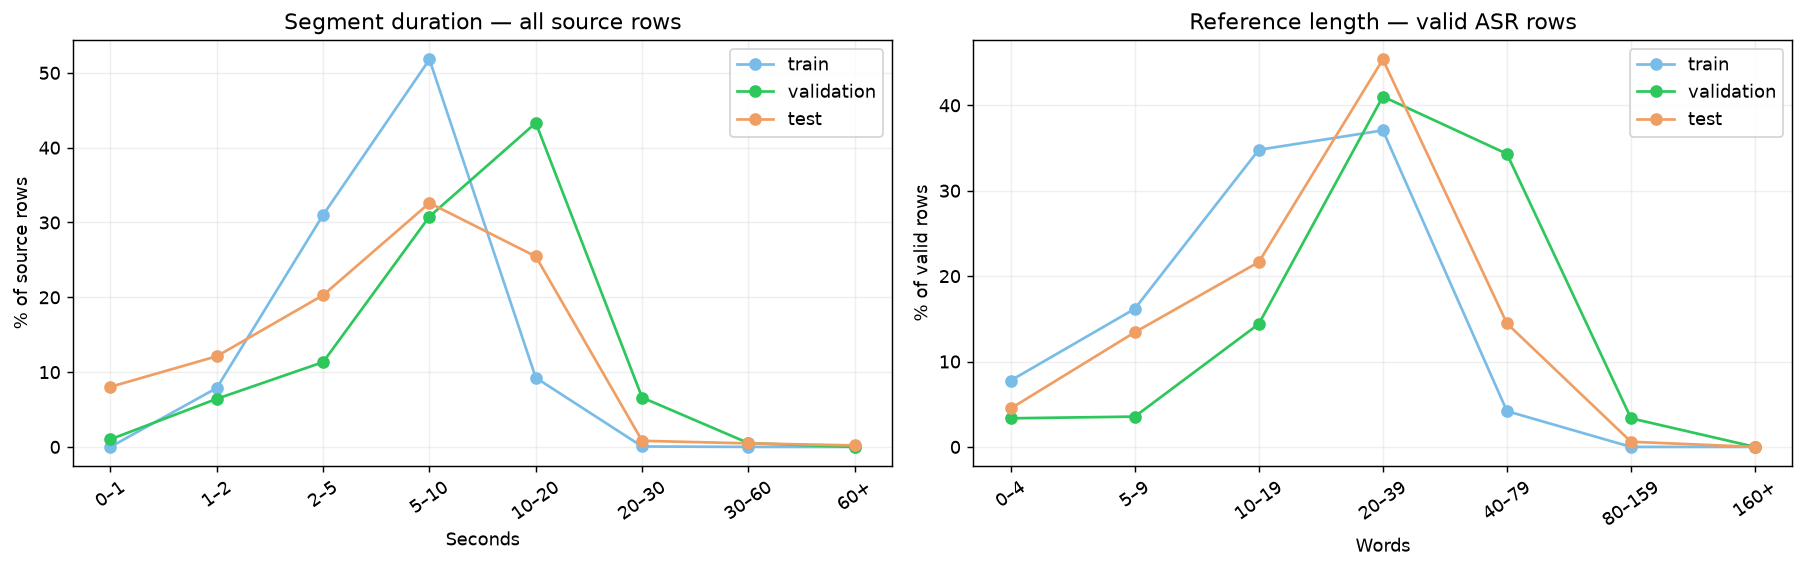

,median_duration_s,p95_duration_s,median_reference_words,p95_reference_words,median_words_per_second
split,,,,,
train,5.96,10.79,17.0,38.0,2.90
validation,10.07,21.50,33.0,73.0,3.09
test,6.92,14.97,24.0,49.0,2.99


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
duration_labels = ["0–1", "1–2", "2–5", "5–10", "10–20", "20–30", "30–60", "60+"]
word_labels = ["0–4", "5–9", "10–19", "20–39", "40–79", "80–159", "160+"]
for name, color in (("train", "#7abce8"), ("validation", "#2dc75c"), ("test", "#ef9f64")):
    r = splits[name]
    d = pd.Series(r["duration_histogram"], dtype=float) / r["rows"] * 100
    w = pd.Series(r["reference_word_histogram"], dtype=float) / r["valid_asr_rows"] * 100
    axes[0].plot(duration_labels, d, marker="o", label=name, color=color)
    axes[1].plot(word_labels, w, marker="o", label=name, color=color)
axes[0].set(title="Segment duration — all source rows", xlabel="Seconds", ylabel="% of source rows")
axes[1].set(title="Reference length — valid ASR rows", xlabel="Words", ylabel="% of valid rows")
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=.2)
    ax.legend()
plt.tight_layout()
plt.show()
summary = pd.DataFrame([
    {"split": n, "median_duration_s": r["duration_quantiles_seconds"]["0.5"],
     "p95_duration_s": r["duration_quantiles_seconds"]["0.95"],
     "median_reference_words": r["reference_word_quantiles"]["0.5"],
     "p95_reference_words": r["reference_word_quantiles"]["0.95"],
     "median_words_per_second": r["wps_quantiles"]["0.5"]}
    for n, r in splits.items()
]).set_index("split")
display(summary.round(2))
print("Interpretation: validation has longer median segments/references than train; split mix differs.")
print("Duration sums are not unique audio hours because intervals overlap.")

## 3. Leakage and quality signals

Shared IDs, speakers and source files are strong split-linkage checks. Exact repeated reference strings are **review signals**, not proof of identical audio. Aggregates cannot identify which row pairs repeat or audit waveform similarity.

In [10]:
overlap = pd.DataFrame(data["cross_split_overlap"])
display(overlap)
quality = pd.DataFrame([
    {"split": n, "repeated_reference_groups": r["repeated_reference_groups"],
     "rows_in_repeated_groups": r["rows_in_repeated_reference_groups"],
     "adjacent_interval_overlaps": r["adjacent_interval_overlaps"],
     "max_duration_s": r["duration_quantiles_seconds"]["1"],
     "max_words_per_second": r["wps_quantiles"]["1"]}
    for n, r in splits.items()
]).set_index("split")
display(quality.round(2))
assert (overlap[["same_ids", "same_speakers", "same_source_files"]] == 0).all().all()
print("Interpretation: no identity/source-file intersection between source splits.")
print("4 / 6 / 2 exact transcript strings recur across train–validation / train–test / validation–test.")
print("Outlier examples and a per-ID duplicate review queue require reacquiring source rows.")

Interpretation: no identity/source-file intersection between source splits.
4 / 6 / 2 exact transcript strings recur across train–validation / train–test / validation–test.
Outlier examples and a per-ID duplicate review queue require reacquiring source rows.


,left,right,same_ids,same_speakers,same_source_files,same_reference_strings
0,train,validation,0,0,0,4
1,train,test,0,0,0,6
2,validation,test,0,0,0,2


,repeated_reference_groups,rows_in_repeated_groups,adjacent_interval_overlaps,max_duration_s,max_words_per_second
split,,,,,
train,1264,4970,126201,30.00,12.03
validation,1,2,3,39.92,6.38
test,1,3,0,330.19,5.83


## 4. Fresh source and waveform audit gate

Set `TEDLIUM3_SOURCE_ROOT` to a reacquired HuggingFace saved-dataset directory with `train/`, `validation/`, `test/`, and `provenance.json`. The receipt pins provenance and split state metadata hashes, which this cell verifies before reading rows. The historical receipt does **not** pin every Arrow shard byte: matching metadata is necessary but insufficient for a new fully verified snapshot. Compare a separately approved shard manifest before lifting HOLD. The next cell decodes every scorable validation/test segment; it does not claim a train–evaluation waveform duplicate audit. No data is downloaded for the Arrow gate. The following sampled-media section reads retained WAV bytes separately.

In [10]:
SOURCE = Path(os.environ.get("TEDLIUM3_SOURCE_ROOT", str(ROOT / "experiments/datasets/tedlium3")))
required = [SOURCE / "provenance.json", *(SOURCE / n / "state.json" for n in splits)]
source_present = all(p.is_file() for p in required)
raw_splits = {}
exclusion_ledger = pd.DataFrame()
if not source_present:
    print("HOLD — Arrow source/provenance absent:", SOURCE)
    print("Fresh row-level IDs, exclusion ledger, examples and waveform decode have NOT run.")
else:
    from datasets import load_from_disk
    for path in required:
        relative = "experiments/datasets/tedlium3/" + path.relative_to(SOURCE).as_posix()
        expected = receipt["source_metadata_sha256"].get(relative)
        assert expected, f"No historical metadata hash for {relative}"
        actual = hashlib.sha256(path.read_bytes()).hexdigest()
        assert actual == expected, f"Historical source metadata mismatch: {relative}"
    for name in ("train", "validation", "test"):
        ds = load_from_disk(str(SOURCE / name))
        assert len(ds) == splits[name]["rows"], f"{name}: row count drift"
        assert {"id", "text", "speaker_id", "file", "audio"} <= set(ds.column_names)
        raw_splits[name] = ds
    ledger_rows = []
    for name in ("validation", "test"):
        for index, row in enumerate(raw_splits[name]):
            ident = str(row.get("id") or "")
            transcript = str(row.get("text") or "").strip()
            ignored = transcript == "ignore_time_segment_in_scoring"
            gap = ident.startswith("inter_segment_gap")
            valid = bool(transcript) and not ignored and not gap
            ledger_rows.append({
                "split": name, "source_index": index, "id": ident,
                "speaker": str(row.get("speaker_id") or ""),
                "source_file": str(row.get("file") or ""),
                "reference_words": len(transcript.split()) if valid else 0,
                "valid_asr": valid,
                "exclusion_reason": "gap/ignore" if gap or ignored else ("blank" if not transcript else ""),
                "reference_preview": transcript[:100] if valid else "",
            })
    ledger = pd.DataFrame(ledger_rows)
    assert ledger.groupby("split").valid_asr.sum().to_dict() == {"validation": 507, "test": 1155}
    exclusion_ledger = ledger.loc[~ledger.valid_asr].copy()
    assert exclusion_ledger.groupby("split").size().to_dict() == {"validation": 84, "test": 314}
    assert not ledger.duplicated(["split", "id"]).any(), "Repeated source IDs need adjudication"
    print("Fresh rows read:", {n: len(ds) for n, ds in raw_splits.items()})
    print("Exclusion ID ledger (first 20 of 398):")
    display(exclusion_ledger[["split", "source_index", "id", "exclusion_reason"]].head(20))
    print("Fixed-rule unusual examples: shortest and longest scorable reference")
    display(pd.concat([ledger[ledger.valid_asr].nsmallest(3, "reference_words"),
                       ledger[ledger.valid_asr].nlargest(3, "reference_words")])
            [["split", "id", "speaker", "source_file", "reference_words", "reference_preview"]])
    print("Metadata hashes match the historical receipt. Arrow shard bytes still require an approved manifest.")


HOLD — Arrow source/provenance absent: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\datasets\tedlium3
Fresh row-level IDs, exclusion ledger, examples and waveform decode have NOT run.


In [10]:
import numpy as np
if not raw_splits:
    print("HOLD — full Arrow waveform audit skipped because verified Arrow source metadata is absent.")
else:
    media_rows, failures = [], []
    for name in ("validation", "test"):
        for index, row in enumerate(raw_splits[name]):
            text = str(row.get("text") or "").strip()
            ident = str(row.get("id") or "")
            if not text or text == "ignore_time_segment_in_scoring" or ident.startswith("inter_segment_gap"):
                continue
            try:
                audio = row["audio"]
                samples = np.asarray(audio["array"], dtype=float)
                rate = int(audio["sampling_rate"])
                if rate <= 0 or samples.ndim != 1 or not len(samples) or not np.isfinite(samples).all():
                    raise ValueError("invalid sample rate, shape, length or finite-value check")
                media_rows.append({"split": name, "id": ident, "sample_rate": rate,
                                   "seconds": len(samples) / rate,
                                   "peak_abs": float(np.max(np.abs(samples))),
                                   "rms": float(np.sqrt(np.mean(samples**2))),
                                   "sha256_pcm": hashlib.sha256(samples.astype("<f4").tobytes()).hexdigest()})
            except Exception as exc:
                failures.append({"split": name, "id": ident, "error": f"{type(exc).__name__}: {exc}"[:200]})
    media = pd.DataFrame(media_rows)
    print("Decoded / expected valid:", len(media), "/", 507 + 1155, "| failures:", len(failures))
    display(media.groupby("split").agg({"id":"count", "sample_rate":["min","max"], "seconds":["min","median","max"], "peak_abs":"max", "rms":"median"}) if len(media) else media)
    display(pd.DataFrame(failures).head(20))
    if len(media):
        hashes_by_split = {n: set(media.loc[media.split == n, "sha256_pcm"]) for n in ("validation", "test")}
        cross_hashes = hashes_by_split["validation"] & hashes_by_split["test"]
        cross_duplicates = media.loc[media.sha256_pcm.isin(cross_hashes)]
        print("Exact PCM duplicate hashes across validation/test:", len(cross_hashes))
        display(cross_duplicates[["split", "id", "sha256_pcm"]].head(20))
    counts = media.groupby("split").size().to_dict() if len(media) else {}
    assert counts == {"validation": 507, "test": 1155}, "Waveform decode incomplete by split"
    assert not failures, "Waveform decode failures must be resolved before qualification"
    print("Evaluation audio decode complete. Train–evaluation duplicate audio and Arrow shard integrity remain HOLD.")


HOLD — full Arrow waveform audit skipped because verified Arrow source metadata is absent.


## 5. Retained 50-unit waveform and reference audit

The 2026-09-26 dataset-readiness bundle is a **separate historical diagnostic sample**, selected by the stored `dataset-readiness-v1` protocol with salt `dataset-readiness-v1`: 30 validation IDs and 20 native-test IDs. This section audits **all 50 selected units**, including eight that lack a usable reference. It loads WAV files from the retained bundle by relative basename, validates both the bundle receipt and each unit's stored SHA-256, then decodes the waveform anew. It does **not** contact Hugging Face, restore the missing Arrow snapshot, or claim corpus-wide media coverage. Re-run requires this retained bundle or a separately verified equivalent. The upstream dataset is [distil-whisper/tedlium, Release 3](https://huggingface.co/datasets/distil-whisper/tedlium); the original source bytes are no longer present here.

Near-silence means 20 ms window RMS < 0.01 full-scale (−40 dBFS). Clipping means sample magnitude ≥ 0.999. These are **screening signals**, not automatic exclusion rules. We compare the decoded sample count to the recorded duration (tolerance 20 ms) and report every failed ID. The historical selection concentrated 18/50 units in one speaker, so these statistics cannot be generalized to all TED-LIUM audio.

In [10]:
from collections import Counter
import numpy as np
import soundfile as sf

BUNDLE = ROOT / "experiments/outputs/dataset_readiness_260926/20260926T101159603902Z/bundle"
bundle_receipt = json.loads((BUNDLE / "bundle-receipt.json").read_text(encoding="utf-8"))
receipt_hashes = {item["path"]: item["sha256"] for item in bundle_receipt["files"]}
for rel in ("tedlium3/units.json", "tedlium3/split-manifest.json", "selection.json", "protocol.json"):
    assert hashlib.sha256((BUNDLE / rel).read_bytes()).hexdigest() == receipt_hashes[rel], rel
units = json.loads((BUNDLE / "tedlium3/units.json").read_text(encoding="utf-8"))
selection = json.loads((BUNDLE / "selection.json").read_text(encoding="utf-8"))
protocol = json.loads((BUNDLE / "protocol.json").read_text(encoding="utf-8"))
assert protocol["version"] == "dataset-readiness-v1"
assert protocol["selection_salt"] == "dataset-readiness-v1"
assert len(units) == 50 and Counter(u["split"] for u in units) == {"validation": 30, "final_test": 20}
assert {u["unit_id"] for u in units} == {u["unit_id"] for u in selection["datasets"]["tedlium3"]["selected"]}
assert len({u["unit_id"] for u in units}) == 50

audit_rows, waveform_failures, waveforms = [], [], {}
for u in units:
    ident = u["unit_id"]
    try:
        rel = "media/tedlium3/" + Path(u["media_path"].replace("\\", "/")).name
        wav_path = BUNDLE / rel
        wav_bytes = wav_path.read_bytes()
        wav_sha = hashlib.sha256(wav_bytes).hexdigest()
        assert wav_sha == receipt_hashes[rel] == u["sha256"], "WAV/receipt/unit SHA-256 mismatch"
        samples, rate = sf.read(wav_path, dtype="float32", always_2d=True)
        assert rate > 0 and len(samples) > 0 and np.isfinite(samples).all()
        seconds = len(samples) / rate
        assert abs(seconds - float(u["duration_sec"])) <= 0.02, "duration differs from stored unit >20 ms"
        mono = samples.mean(axis=1)
        block = max(1, round(rate * 0.02))
        window_rms = np.array([np.sqrt(np.mean(mono[i:i + block] ** 2))
                               for i in range(0, len(mono), block)])
        label_valid = bool(str(u.get("reference_text") or "").strip()) and not u.get("ground_truth_error")
        row = {
            "split": u["split"], "unit_id": ident, "speaker": u["speaker_id"],
            "source_file": u["source_id"], "label_valid": label_valid,
            "decision": u["decision"], "duration_s": round(seconds, 3),
            "sample_rate_hz": rate, "channels": samples.shape[1],
            "peak_abs": round(float(np.max(np.abs(samples))), 5),
            "rms": round(float(np.sqrt(np.mean(samples.astype("float64") ** 2))), 5),
            "clipped_samples": int(np.count_nonzero(np.abs(samples) >= 0.999)),
            "near_silent_20ms_pct": round(100 * float(np.mean(window_rms < 0.01)), 2),
            "wav_sha256": wav_sha,
            "reference_words": len(str(u.get("reference_text") or "").split()) if label_valid else 0,
            "reference_preview": str(u.get("reference_text") or "")[:115] if label_valid else "",
            "label_issue": u.get("ground_truth_error") or "",
        }
        audit_rows.append(row)
        waveforms[ident] = (mono, rate)
    except Exception as exc:
        waveform_failures.append({"unit_id": ident, "error": f"{type(exc).__name__}: {exc}"[:240]})
audit = pd.DataFrame(audit_rows)
print("Bundle:", BUNDLE)
print("Bundle receipt SHA-256:", hashlib.sha256((BUNDLE / "bundle-receipt.json").read_bytes()).hexdigest())
print("Selection SHA-256:", receipt_hashes["selection.json"], "| units SHA-256:", receipt_hashes["tedlium3/units.json"])
print("Selected / WAV observed / label-valid / media-valid / evaluated / failed:",
      len(units), "/", len(audit), "/", int(audit.label_valid.sum()), "/", len(audit), "/ 0 /", len(waveform_failures))
print("Stored selection protocol:", protocol["version"], "salt:", protocol["selection_salt"])
display(audit.groupby("split").agg(selected=("unit_id", "count"),
                                  label_valid=("label_valid", "sum"),
                                  sample_rate_min=("sample_rate_hz", "min"),
                                  sample_rate_max=("sample_rate_hz", "max"),
                                  duration_median_s=("duration_s", "median"),
                                  near_silence_median_pct=("near_silent_20ms_pct", "median")))
print("First 6 selected IDs and reference examples:")
display(audit[["split", "unit_id", "speaker", "duration_s", "peak_abs",
               "rms", "near_silent_20ms_pct", "reference_preview"]].head(6))
print("Eight reference-invalid IDs; WAV decode can still pass:")
display(audit.loc[~audit.label_valid, ["split", "unit_id", "label_issue", "duration_s"]])
print("Highest near-silence and longest duration:")
display(pd.concat([audit.nlargest(3, "near_silent_20ms_pct"),
                   audit.nlargest(3, "duration_s")])
        [["split", "unit_id", "duration_s", "peak_abs", "rms",
          "clipped_samples", "near_silent_20ms_pct", "reference_preview"]])
print("Waveform read/hash failures:")
display(pd.DataFrame(waveform_failures))
assert len(audit) == len(units) == 50 and not waveform_failures
assert int(audit.label_valid.sum()) == 42
print("Warning: 50 stored historical WAVs re-decoded; original Arrow source was not reacquired.")


Bundle: C:\Users\hung\Documents\GitHub\multimodal-lecture-summarizer\benchmark\experiments\outputs\dataset_readiness_260926\20260926T101159603902Z\bundle
Bundle receipt SHA-256: 2d840665ebbcb2ee193a23ad5818e671b813026a70d52f357e1a17ccf08a80a6
Selection SHA-256: a9881452bbacbbe5f241e63e52546e27d3c6610b3b1de0a0be63902d56f6724e | units SHA-256: 0c48379822172653e1be5bfb53a91d2a7d5d44ffe5c02c57a3187df9f8a47dfb
Selected / WAV observed / label-valid / media-valid / evaluated / failed: 50 / 50 / 42 / 50 / 0 / 0
Stored selection protocol: dataset-readiness-v1 salt: dataset-readiness-v1
First 6 selected IDs and reference examples:
Eight reference-invalid IDs; WAV decode can still pass:
Highest near-silence and longest duration:
Waveform read/hash failures:


,selected,label_valid,sample_rate_min,sample_rate_max,duration_median_s,near_silence_median_pct
split,,,,,,
final_test,20,16,16000,16000,7.235,27.09
validation,30,26,16000,16000,9.241,16.23


,split,unit_id,speaker,duration_s,peak_abs,rms,near_silent_20ms_pct,reference_preview
0,validation,validation:Wade_Davis-877.86-885.24-<F0_M>,Wade_Davis,7.38,0.64273,0.06673,18.97,passively accepted the massive destruction of both biological and cultural diversity on the planet now the problem
1,validation,validation:Wade_Davis-753.79-774.30-<F0_M>,Wade_Davis,20.51,0.59937,0.07823,6.53,distortion of reality it creates the dissolution of reality in fact i used to argue with my professor richard evan
2,validation,validation:S54-336.83-342.06-<F0_M>,S54,5.23,0.24368,0.08037,0.00,
3,validation,validation:Brian_Cox-13.16-23.36-<F0_M>,Brian_Cox,10.20,0.65067,0.06163,16.27,last year at ted i gave an introduction to the lhc and i promised to come back and give you an update on how that m
4,validation,validation:Wade_Davis-1045.71-1054.34-<F0_M>,Wade_Davis,8.63,0.51285,0.09007,12.50,and in the end then it really comes down to a choice do we want to live in a monochromatic world of monotony or do
5,validation,validation:Wade_Davis-1252.88-1262.43-<F0_M>,Wade_Davis,9.55,0.54132,0.07730,24.69,the naked geography of hope so what we 're trying to do at the national geographic finally is we believe that polit


,split,unit_id,label_issue,duration_s
2,validation,validation:S54-336.83-342.06-<F0_M>,empty_or_ignore_reference,5.230
17,validation,validation:S32-200.61-209.82-<F0_M>,empty_or_ignore_reference,9.182
21,validation,validation:S54-420.82-429.29-<F0_M>,empty_or_ignore_reference,8.447
28,validation,validation:S33-251.59-254.17-<F0_M>,empty_or_ignore_reference,2.580
32,final_test,"final_test:inter_segment_gap-313.16-314.63-<o,,unknown>",empty_or_ignore_reference,1.470
35,final_test,"final_test:inter_segment_gap-0-16.11-<o,,unknown>",empty_or_ignore_reference,16.110
45,final_test,"final_test:inter_segment_gap-972.154-975.758-<o,,unknown>",empty_or_ignore_reference,3.604
49,final_test,"final_test:inter_segment_gap-201.92-202.722-<o,,unknown>",empty_or_ignore_reference,0.802


,split,unit_id,duration_s,peak_abs,rms,clipped_samples,near_silent_20ms_pct,reference_preview
49,final_test,"final_test:inter_segment_gap-201.92-202.722-<o,,unknown>",0.802,0.01355,0.00167,0,100.00,
32,final_test,"final_test:inter_segment_gap-313.16-314.63-<o,,unknown>",1.470,0.04691,0.00806,0,81.08,
33,final_test,"final_test:AimeeMullins-49.3398-56.39-<o,f0,female>",7.050,0.72391,0.03905,0,47.88,stalled maimed wounded mangled lame mutilated
25,validation,validation:Wade_Davis-539.44-569.45-<F0_M>,30.010,0.69028,0.08026,0,16.19,are inculturated into the values of their society values that maintain the proposition that their prayers and their
24,validation,validation:Wade_Davis-12.51-34.52-<F0_M>,22.010,0.63464,0.07195,0,17.44,you know one of the intense pleasures of travel and one of the delights of ethnographic research is the opportunity
11,validation,validation:Wade_Davis-305.16-327.12-<F0_M>,21.960,0.64914,0.07541,0,10.29,do not distinguish the color blue from the color green because the canopy of the heavens is equated to the canopy o


""


Screen counts: {'sample_rate_16k': 50, 'mono': 50, 'clipped_units': 0, 'over_50pct_near_silent': 2}


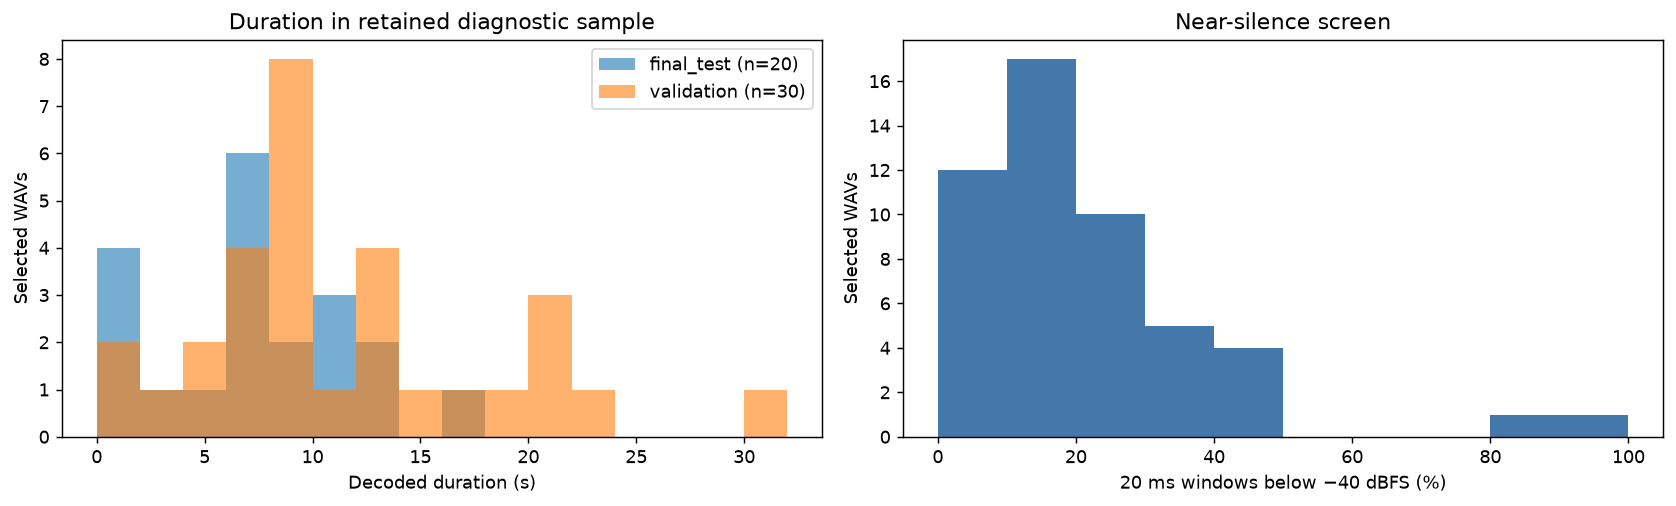

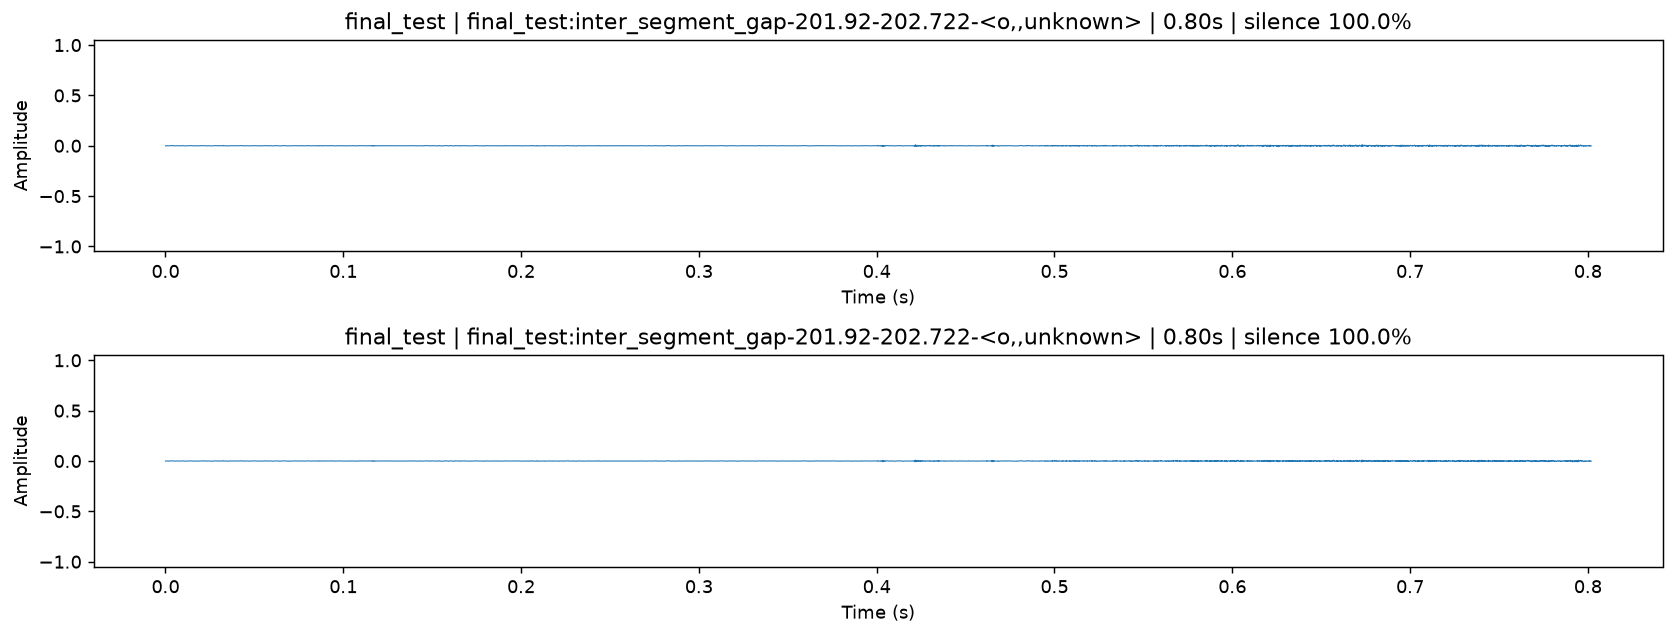

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split, group in audit.groupby("split"):
    axes[0].hist(group["duration_s"], bins=np.arange(0, 33, 2), alpha=0.6,
                 label=f"{split} (n={len(group)})")
axes[0].set(xlabel="Decoded duration (s)", ylabel="Selected WAVs",
            title="Duration in retained diagnostic sample")
axes[0].legend()
axes[1].hist(audit["near_silent_20ms_pct"], bins=np.arange(0, 105, 10), color="#4477aa")
axes[1].set(xlabel="20 ms windows below −40 dBFS (%)", ylabel="Selected WAVs",
            title="Near-silence screen")
plt.tight_layout()
plt.show()

examples = [audit.loc[audit.duration_s.idxmin()],
            audit.loc[audit.near_silent_20ms_pct.idxmax()]]
fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for ax, row in zip(axes, examples):
    signal, rate = waveforms[row.unit_id]
    stride = max(1, len(signal) // 5000)
    ax.plot(np.arange(0, len(signal), stride) / rate, signal[::stride], linewidth=0.6)
    ax.set(xlabel="Time (s)", ylabel="Amplitude",
           title=f"{row.split} | {row.unit_id} | {row.duration_s:.2f}s | silence {row.near_silent_20ms_pct:.1f}%")
    ax.set_ylim(-1.05, 1.05)
plt.tight_layout()
plt.show()
print("Screen counts:", {"sample_rate_16k": int((audit.sample_rate_hz == 16000).sum()),
                        "mono": int((audit.channels == 1).sum()),
                        "clipped_units": int((audit.clipped_samples > 0).sum()),
                        "over_50pct_near_silent": int((audit.near_silent_20ms_pct > 50).sum())})


## 6. Decision and limits

The historical aggregate still covers 270,323 source rows. The original Arrow snapshot was **not reacquired or rescanned**, so full row-level exclusion and full media qualification remain HOLD. The independently verified retained readiness bundle below provides row IDs, reference examples, and a **fresh decode of its 50 stored WAV files** under the prior deterministic selection protocol. It is a convenience/diagnostic subset, not a random representative sample of the corpus. Its 20 native-test rows were previously observed, so this is diagnostic and not an unseen final test. These waveform checks do not rerun ASR models and do not change any model benchmark claim.

Source: `experiments/outputs/full_corpus_eda_261003/eda_receipt.json` and `tedlium3.json` for the historical aggregate; `experiments/outputs/dataset_readiness_260926/20260926T101159603902Z/bundle/` for 50 sampled WAVs and their hash-listed local receipt. The notebook checks the source bytes on every run.

## Qualification follow-up — 2026-10-10

Earlier executed outputs are retained as historical evidence. This additive review supersedes their current availability/qualification statements where explicitly recorded in the receipt. KEEP and REPAIR are scoped record-quality decisions, not approval of a benchmark cohort.

In [11]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Markdown, Image
saved = json.loads('{"dataset": "tedlium3", "observed_at_utc": "2026-10-10T08:56:21.879253+00:00", "counts": {"selected": 50, "observed": 50, "label_valid": 42, "media_valid": 50, "evaluated": 0, "failed": 0}, "artifacts": [{"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\tedlium3-id-ledger.csv", "sha256": "ded2e9d9c4bce066932aa59e49b261d58493cb5447fe61ec84d6ddd8212a764e", "rows": 50}, {"path": "experiments\\\\outputs\\\\dataset_qualification_261010\\\\tedlium-recovery-probes.json", "sha256": "1be7e2ac9ab98fd293b5d792c4c16cb6644237c3cfb56254967221fdf0911dd3"}], "model_inference_run": false, "unseen_reference_claim": false, "decisions": {"KEEP": 42, "EXCLUDE": 8}, "source_group_intersection": [], "invalid_trace": {"ignore_marker": 8, "validation_ignore": 4, "test_gap_ignore": 4}, "source_recovery": {"original_pin": "local Arrow fingerprint, not an upstream Git commit", "builder_probed_revision": "db6c0314dee6cc8e2770b34fda08f4a3bf1ebd59", "builder_preserves_ignore_marker": true, "LIUM_API_status": 401, "original_Arrow_bytes_recovered": false}, "media_scope": "reuse prior 50-WAV decode, reverify immutable file hashes; no full-corpus decode", "status": "bounded_42_item_diagnostic_candidate_only_no_scientific_freeze"}')
roots = [Path.cwd(), *Path.cwd().parents]
root = next((p for p in roots if (p / "experiments/notebooks/notebook_manifest.yaml").is_file()), None)
receipt_path = root / "experiments/outputs/dataset_qualification_261010/tedlium3-qualification-receipt.json" if root else None
if receipt_path is not None and receipt_path.is_file():
    assert hashlib.sha256(receipt_path.read_bytes()).hexdigest() == '63d31b004874198e983dfffc80c70fdb1d10a39a709c7028ed2e86cd2edbb415', "Receipt changed: review and regenerate this section."
    evidence = json.loads(receipt_path.read_text(encoding="utf-8"))
    display(Markdown("**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models."))
else:
    evidence = saved
    display(Markdown("**Embedded historical snapshot only:** local qualification files unavailable. This is not a new acquisition or audit."))
display(pd.DataFrame([evidence["counts"]]))
display(Markdown("**Status:** " + str(evidence.get("status", "HOLD; cohort not frozen"))))
details = {k:v for k,v in evidence.items() if k not in {"counts", "artifacts"}}
display(pd.DataFrame([{"field":k, "value":json.dumps(v, ensure_ascii=False)} for k,v in details.items()]))
for item in evidence.get("artifacts", []):
    relative = item["path"].replace("\\", "/")
    display(Markdown("Evidence: `" + relative + "` · SHA-256 `" + item["sha256"] + "`"))
    path = root / relative if root else None
    if path is None or not path.is_file():
        continue
    assert hashlib.sha256(path.read_bytes()).hexdigest() == item["sha256"], "Evidence hash changed: " + relative
    if path.suffix == ".csv" and path.stat().st_size > 5:
        table = pd.read_csv(path)
        # Show decisions and coordinates; avoid exposing more answer/reference content.
        safe = [c for c in table.columns if c not in {"reference_text", "question", "answer"}]
        display(Markdown(str(len(table)) + " ledger rows; first 20 shown below. Full ledger remains linked above."))
        display(table[safe].head(20))
    elif path.name.endswith("geometry-contact-sheet.png"):
        display(Image(filename=str(path), width=1000))
display(Markdown("**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**"))


**Saved qualification receipt loaded and hash verified.** This cell does not decode media or run models.

,selected,observed,label_valid,media_valid,evaluated,failed
0,50,50,42,50,0,0


**Status:** bounded_42_item_diagnostic_candidate_only_no_scientific_freeze

,field,value
0,dataset,"""tedlium3"""
1,observed_at_utc,"""2026-10-10T08:56:21.879253+00:00"""
2,model_inference_run,false
3,unseen_reference_claim,false
4,decisions,"{""KEEP"": 42, ""EXCLUDE"": 8}"
5,source_group_intersection,[]
6,invalid_trace,"{""ignore_marker"": 8, ""validation_ignore"": 4, ""..."
7,source_recovery,"{""original_pin"": ""local Arrow fingerprint, not..."
8,media_scope,"""reuse prior 50-WAV decode, reverify immutable..."
9,status,"""bounded_42_item_diagnostic_candidate_only_no_..."


Evidence: `experiments/outputs/dataset_qualification_261010/tedlium3-id-ledger.csv` · SHA-256 `ded2e9d9c4bce066932aa59e49b261d58493cb5447fe61ec84d6ddd8212a764e`

50 ledger rows; first 20 shown below. Full ledger remains linked above.

,id,split,source_group,arrow_coordinate,annotation_sha256,media_sha256,media_valid,label_valid,decision,reason,scientific_cohort_status,evidence
0,validation:Wade_Davis-877.86-885.24-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,be2236b12d04815ffca7a5436a5a89d687c6c79d5ca355...,e3f944ff82ef3eadd0d60fc7ed1286e84ed0eeba3f6ef4...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
1,validation:Wade_Davis-753.79-774.30-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,8e2f7365ce8d58427960ba35c896a9e3dfcbc6fe7196f7...,54a3c27b8d377755f05d0108b19b24c2bb7f8448c24f1a...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
2,validation:S54-336.83-342.06-<F0_M>,validation,DavidMerrill_2009.sph,experiments/datasets/tedlium3/validation/data-...,061690153da6a2b7bda12125872517533fcfaf4b05d38c...,7e78ff294ba950d3d6c7f822201effa321b23c7e3ac3cf...,True,False,EXCLUDE,source_ignore_marker,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
3,validation:Brian_Cox-13.16-23.36-<F0_M>,validation,BrianCox_2009U.sph,experiments/datasets/tedlium3/validation/data-...,cebdc659a29f1f01b3598bdbbc813f5870274e6aced9d6...,27b06b244f4e4fee291a3e6b1b29effd5b7a6ec0ed30d4...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
4,validation:Wade_Davis-1045.71-1054.34-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,9553dd0cbbeec6de5ef123311482647c1240a283da7c6d...,78b00f97f303181c95efe505664adf4fb89df37f616ddf...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
5,validation:Wade_Davis-1252.88-1262.43-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,7014ea828f31c2512f48509389cf600c3877d35a3ea09e...,17de0837c13ac5b5ff9e245e15f6504541259feac4c259...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
6,validation:Wade_Davis-1149.78-1156.64-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,1cdce162d2b97fc34db566fec2b175094929c3a115e3f8...,1e867ecae64280dd6d4d06d9eb7ff616c3b03c57ce3a08...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
7,validation:Wade_Davis-986.13-991.66-<F0_M>,validation,WadeDavis_2003.sph,experiments/datasets/tedlium3/validation/data-...,1cc1b327e530738042989d421ebffb7a7c99a6fd70cbf6...,b08cb42ea8364c366bde3c07599b55b6289ba0bcbb8b77...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
8,validation:Brian_Cox-193.78-200.61-<F0_M>,validation,BrianCox_2009U.sph,experiments/datasets/tedlium3/validation/data-...,8d4111834039664f43cd4f3f73bda21089216c0eac9db3...,7b5552a5caa47ea8d58f6a029f22195714f41cadbe5b94...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...
9,validation:David_Merrill-99.81-107.29-<F0_M>,validation,DavidMerrill_2009.sph,experiments/datasets/tedlium3/validation/data-...,3e702ebd9403118ce14ed77315605048a3cc3d5f8e6193...,49befc19623594eba0d011bae76c69e9bbf4c938423705...,True,True,KEEP,released_reference_for_bounded_ASR_diagnostic,HOLD_source_snapshot_and_independent_holdout,retained_bundle_hash_verified; prior_50_WAV_de...


Evidence: `experiments/outputs/dataset_qualification_261010/tedlium-recovery-probes.json` · SHA-256 `1be7e2ac9ab98fd293b5d792c4c16cb6644237c3cfb56254967221fdf0911dd3`

**No scientific cohort/protocol freeze. Native test references inspected in EDA cannot be described as unseen. Evaluated counts here refer to new model evaluations in this follow-up.**